<a href="https://colab.research.google.com/github/JosefBirnoecker/Strukturbioinformatik_Projekt/blob/main/ex02/ex02_workbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 02 Workbook: your own protein

This notebook is **deliberately almost empty**, and it is entirely about **your** protein: the
one on your ex01 Character Sheet, which you carry through ex03, ex04 and your final project.

Its companion, **`ex02_guide.ipynb`**, works everything through on human p53 and PDB 3D08.
**Read the guide first**, then work here with it open beside you. The sections below carry the
same numbers as the guide's: A.1 to A.3, then B.1 to B.3.

## How to work in this notebook

- **Copy code from the guide and adapt it.** Its helpers work on any protein with an
  AlphaFold DB entry.
- **Structure the notebook however you like.** The sections are a checklist, not a template.
- **The reasoning is graded, not the code.** Every section asks for a written conclusion.
- **No GPU here.** B.1's AlphaFold 3 run happens in ColabFold's notebook, on
  Colab's free GPU.

**Time: about 45 to 60 minutes**, plus the wait for AlphaFold 3. **What you will not learn
here** is anything the guide did not show: every section asks for a guide step, repeated on
your protein.

## Using AI tools

You may use AI assistants for syntax, debugging and code snippets. You must supply the
predictions, the critical evaluation and the biological reasoning. **"The AI said so" is not
an answer.**

**Predict-first prompts** (A.1 and B.1) ask for your prediction *before* you run
anything. That written prediction is the graded artefact. Being wrong costs nothing; not
predicting costs the marks.

## Setup

Copy the guide's setup cell here and run it first. A Colab notebook starts empty, so
nothing from the guide's session carries over here.

In [1]:
#@title Setup {display-mode: "form"}
# Setup. Everything in this notebook runs on a plain CPU runtime.
try:
    from google.colab import drive  # noqa: F401  (import is the availability test)

    is_google_colab = True
except ImportError:
    is_google_colab = False

if is_google_colab:
    %pip install numpy==2.1.3 pandas==2.2.3 matplotlib==3.10.0 py3dmol==2.4.0 mdanalysis==2.10.0 biopython==1.85 rdkit==2026.3.5

import warnings

warnings.filterwarnings("ignore")

import json
import os
import re
import tempfile
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
import py3Dmol
import requests
from Bio.PDB import PDBIO, MMCIFParser
from MDAnalysis.analysis import align, distances
from rdkit import Chem
from rdkit.Chem import rdMolAlign

print("Libraries loaded -- no GPU needed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 103.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.4 MB/s eta 0:00:00


Libraries loaded -- no GPU needed


---

## Your structure: the crystal from ex01

This notebook works on **the crystal you chose in ex01**, the PDB entry on your Character
Sheet, and on no other: not another entry of the same protein, even a sharper one. The
residue numbers you carry from one exercise to the next belong to that entry. Every
candidate numbers its residues the way UniProt does, so they also line up with both AlphaFold models, as long as B.1 gets your whole
UniProt sequence.

Put its PDB ID at the top of your first code cell, as `PDB_ID = "..."`, and use `PDB_ID`
wherever the guide names its own entry.

---

# Part A: Your protein's AlphaFold prediction

## A.1 Predict first, before you fetch anything

**Before you look at any number**, predict: will confidence be uniform or split, and where?
Base it on your ex01 findings: the residues your crystal failed to resolve, and those with the
highest B-factors. A wrong prediction with stated reasoning earns full marks; "I don't know"
earns none.

Protein missing from [the AlphaFold Database](https://alphafold.ebi.ac.uk/)? Use the
[AlphaFold Server](https://alphafoldserver.com/welcome) or
[ColabFold](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb).

> **My prediction:** We expect high confidence across most of the sequence, but with noticeable drops in the regions that exhibited the highest B-factors in our crystal.
>
> **My reasoning (citing my ex01 findings):**  Shikimate kinase (Uniprot: P9WPY3) has 176 residues, while 2IYS´s crystal resolved residues 2-176 without gaps. We observed elevated B-factors around residues 100-120, 150-155 and 170-176. While the crystal structure did successfully resolve these residues, we expect structural predictors to reflect lower confidence in these regions with inherent flexibility.

## A.2 Confidence analysis

Produce, for your protein: the global mean pLDDT, a per-residue **pLDDT plot**, a **PAE
heatmap** and the four `fractionPlddt*` bands.

**Then answer:**

- Where is pLDDT above 90, and where below 70? Why there: core, surface, loops, termini?
- Which parts does the PAE place confidently relative to each other, and which not?
- Is your protein uniformly mediocre, or excellent in one region and uncertain elsewhere?
- How did your A.1 prediction hold up? If it was wrong, what did you miss?

In [3]:
def prediction_record(uniprot: str, fragment: int = 1) -> pd.Series:
    """AlphaFold DB's record for one UniProt accession, as a single row.

    The record carries the summary metrics and the URLs of every other file, so nothing
    below ever builds an AlphaFold DB URL by hand. Very long proteins come back as more
    than one fragment; most, including p53, fit in `F1`.
    """
    entries = pd.json_normalize(
        requests.get(f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot}").json()
    )
    return entries.set_index("modelEntityId").loc[f"AF-{uniprot}-F{fragment}"]


def download_prediction_files(entry: pd.Series, directory: Path) -> dict[str, Path]:
    """Save the three files the record points at. Returns {name: path}.

    A URL the database does not serve is reported and skipped rather than stopping the
    download of the others.
    """
    directory.mkdir(exist_ok=True)
    wanted = {"model.pdb": "pdbUrl", "confidence.json": "plddtDocUrl", "pae.json": "paeDocUrl"}
    saved = {}
    for name, field in wanted.items():
        response = requests.get(entry[field])
        target = directory / f"{entry.name}-{name}"
        if response.status_code != 200:
            print(f"    {name:<18} HTTP {response.status_code}  <-- unavailable, skipped")
            continue
        target.write_bytes(response.content)
        saved[name] = target
        print(f"    {name:<18} {len(response.content):>9,} bytes  -> {target}")
    return saved


def per_residue_confidence(entry: pd.Series) -> pd.DataFrame:
    """PLDDT and its confidence category, indexed by residue number.

    The file is three parallel arrays, which is already a table. Indexing by residue
    number means slicing a range later reads like the biology.
    """
    return (
        pd.read_json(entry["plddtDocUrl"])
        .rename(columns={"confidenceScore": "pLDDT", "confidenceCategory": "category"})
        .set_index("residueNumber")
    )


def pae_matrix(entry: pd.Series) -> pd.DataFrame:
    """The n x n predicted aligned error, indexed by residue number on both axes."""
    record = pd.read_json(entry["paeDocUrl"]).iloc[0]
    pae = pd.DataFrame(record["predicted_aligned_error"])
    pae.index += 1              # residue numbering starts at 1, not 0
    pae.columns += 1
    return pae


def confidence_bands(entry: pd.Series) -> pd.Series:
    """The four fractionPlddt* bands, as a Series labelled by their pLDDT range."""
    labels = {
        "fractionPlddtVeryLow": "Very low (<50)",
        "fractionPlddtLow": "Low (50-70)",
        "fractionPlddtConfident": "Confident (70-90)",
        "fractionPlddtVeryHigh": "Very high (>90)",
    }
    return pd.Series({label: entry[field] for field, label in labels.items()})


In [5]:
UNIPROT = "P9WPY3"          # shikimate kinase
DATA = Path("afdb_data")
DATA.mkdir(exist_ok=True)

entry = prediction_record(uniprot=UNIPROT)
(DATA / f"afdb_{UNIPROT}.json").write_text(entry.to_json(indent=2))

print(f"Model: {entry.name}  (pipeline: {entry['toolUsed']})")
print(f"Sequence length: {entry['sequenceEnd'] - entry['sequenceStart'] + 1} residues")
print(f"Global mean pLDDT: {entry['globalMetricValue']:.1f}\n")

print("  provenance, and the fields used below:")
for key in ("modelCreatedDate", "latestVersion", "uniprotSequence", "globalMetricValue",
            "pdbUrl", "plddtDocUrl", "paeDocUrl"):
    if key in entry:
        value = entry[key]
        shown = f"{value[:52]}..." if isinstance(value, str) and len(value) > 55 else value
        print(f"    {key:<20} {shown}")

print("\n  downloading:")
files = download_prediction_files(entry=entry, directory=DATA)

Model: AF-P9WPY3-F1  (pipeline: AlphaFold Monomer v2.0 pipeline)
Sequence length: 176 residues
Global mean pLDDT: 91.5

  provenance, and the fields used below:
    modelCreatedDate     2025-08-01T00:00:00Z
    latestVersion        6
    uniprotSequence      MAPKAVLVGLPGSGKSTIGRRLAKALGVGLLDTDVAIEQRTGRSIADIFATD...
    globalMetricValue    91.5
    pdbUrl               https://alphafold.ebi.ac.uk/files/AF-P9WPY3-F1-model...
    plddtDocUrl          https://alphafold.ebi.ac.uk/files/AF-P9WPY3-F1-confi...
    paeDocUrl            https://alphafold.ebi.ac.uk/files/AF-P9WPY3-F1-predi...

  downloading:
    model.pdb            110,888 bytes  -> afdb_data/AF-P9WPY3-F1-model.pdb
    confidence.json        2,397 bytes  -> afdb_data/AF-P9WPY3-F1-confidence.json
    pae.json              67,883 bytes  -> afdb_data/AF-P9WPY3-F1-pae.json


## File shapes

In [7]:
conf = json.loads(files["confidence.json"].read_text())
print("confidence.json")
print(f"  keys        : {list(conf.keys())}")
print(f"  n residues  : {len(conf['residueNumber'])}")
print(f"  first 5     : residue {conf['residueNumber'][:5]}")
print(f"                score   {conf['confidenceScore'][:5]}")
print(f"                category{conf['confidenceCategory'][:5]}   (D/L/M/H = disordered->high)")

pae_obj = json.loads(files["pae.json"].read_text())[0]
print("\npae.json")
print(f"  keys        : {list(pae_obj.keys())}")
print(f"  matrix      : {len(pae_obj['predicted_aligned_error'])} x "
      f"{len(pae_obj['predicted_aligned_error'][0])}")
print(f"  max_predicted_aligned_error = {pae_obj['max_predicted_aligned_error']}")

atom_lines = [line for line in files["model.pdb"].read_text().splitlines()
              if line.startswith("ATOM")]
print("\nmodel.pdb")
print(f"  ATOM records: {len(atom_lines):,}")
print(f"  first ATOM  : {atom_lines[0][:66]}")
print("                                                     ^^^^^^ B-factor column = pLDDT")

# Prove the B-factor column really is the pLDDT from confidence.json
first_ca = next(line for line in atom_lines if line[12:16].strip() == "CA")
print(f"\n  residue 1 pLDDT from confidence.json : {conf['confidenceScore'][0]}")
print(f"  residue 1 B-factor from model.pdb    : {float(first_ca[60:66])}")

confidence.json
  keys        : ['residueNumber', 'confidenceScore', 'confidenceCategory']
  n residues  : 176
  first 5     : residue [1, 2, 3, 4, 5]
                score   [81.88, 91.69, 97.31, 96.94, 98.06]
                category['M', 'H', 'H', 'H', 'H']   (D/L/M/H = disordered->high)

pae.json
  keys        : ['predicted_aligned_error', 'max_predicted_aligned_error']
  matrix      : 176 x 176
  max_predicted_aligned_error = 31.75

model.pdb
  ATOM records: 1,306
  first ATOM  : ATOM      1  N   MET A   1      -2.311  -6.813  20.411  1.00 81.88
                                                     ^^^^^^ B-factor column = pLDDT

  residue 1 pLDDT from confidence.json : 81.88
  residue 1 B-factor from model.pdb    : 81.88


### pLDDT along the sequence

In [8]:
def plot_plddt(confidence: pd.DataFrame, highlight: tuple[int, int] | None = None,
               title: str | None = None, ax: plt.Axes | None = None,
               label: str = "AlphaFold DB") -> plt.Axes:
    """PLDDT along the sequence. `highlight` shades a (start, end) residue range."""
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 4))
    ax.plot(confidence.index, confidence["pLDDT"], color="tab:blue", lw=1, label=label)
    ax.axhline(90, color="grey", ls=":", lw=1, label="pLDDT = 90 (very high)")
    ax.axhline(70, color="grey", ls="--", lw=1, label="pLDDT = 70 (confident cutoff)")
    if highlight is not None:
        ax.axvspan(highlight[0], highlight[1], color="tab:green", alpha=0.15,
                   label=f"resolved range ({highlight[0]}-{highlight[1]})")
    ax.set_xlabel("Residue number")
    ax.set_ylabel("pLDDT")
    ax.set_ylim(0, 100)
    ax.set_title(title or "AlphaFold DB per-residue confidence")
    ax.legend(loc="lower center")
    return ax


def plot_pae(pae: pd.DataFrame | np.ndarray,
             title: str = "Predicted Aligned Error (PAE)",
             ax: plt.Axes | None = None) -> plt.Axes:
    """The PAE matrix as a heatmap, dark = confident.

    Row i, column j is the error at residue j when the structures are aligned on residue
    i. Takes the DataFrame from `pae_matrix` or a plain array, such as AlphaFold 3's `pae`.
    """
    values = np.asarray(pae)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(values, cmap="Greens_r", vmin=0, vmax=values.max(),
                   extent=[1, values.shape[1], values.shape[0], 1])
    ax.set_xlabel("Scored residue")
    ax.set_ylabel("Aligned residue")
    ax.set_title(title)
    ax.figure.colorbar(im, ax=ax, label="Expected error (A)")
    return ax


In [9]:
confidence = per_residue_confidence(entry=entry)

CRYSTAL_START, CRYSTAL_END = 2, 176        # 2IYS's own resolved range
core = confidence.loc[CRYSTAL_START:CRYSTAL_END, "pLDDT"]

print(f"AlphaFold mean pLDDT over 2IYS's resolved range "
      f"({CRYSTAL_START}-{CRYSTAL_END}): {core.mean():.1f}")
print(f"Fraction of that range with pLDDT < 70: {(core < 70).mean()*100:.1f}%")

AlphaFold mean pLDDT over 2IYS's resolved range (2-176): 91.6
Fraction of that range with pLDDT < 70: 7.4%


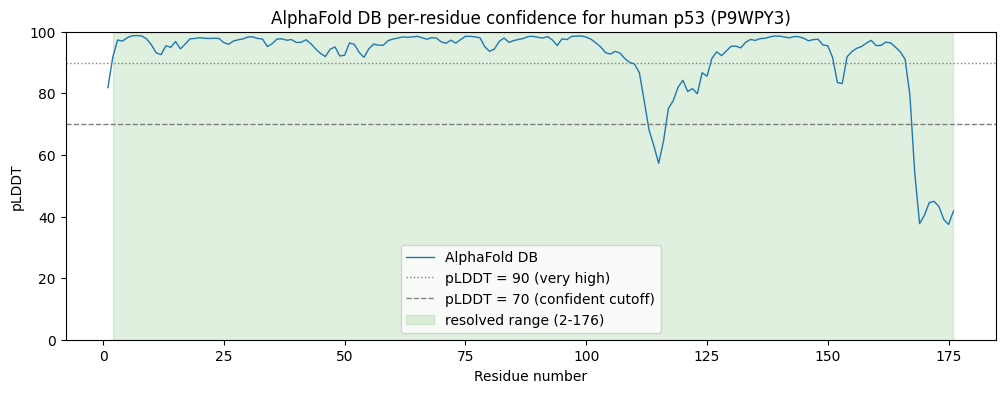

In [10]:
plot_plddt(confidence=confidence, highlight=(CRYSTAL_START, CRYSTAL_END),
           title=f"AlphaFold DB per-residue confidence for human p53 ({UNIPROT})")
plt.show()

**Where is pLDDT above 90, and where below 70? Why there: core, surface, loops, termini?**  
plDDT is above 90 in most of our residues. It drops below 90 at the N-terminus and the loop region 150-155. Furthermore it drops below 70 around 120, which corresponds to our loop region 100-120 and at the C-Terminus.

### Predicted Aligned Error (PAE)


PAE matrix: 176 x 176 residues
Largest expected error in this entry: 30.0 A


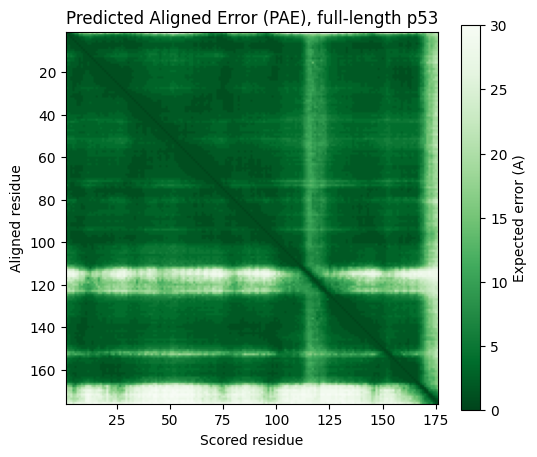


Mean PAE within the core domain  : 5.8 A
Mean PAE core vs. N-terminal tail : 6.3 A


In [11]:
pae = pae_matrix(entry=entry)
print(f"PAE matrix: {pae.shape[0]} x {pae.shape[1]} residues")
print(f"Largest expected error in this entry: {pae.values.max():.1f} A")

plot_pae(pae=pae, title="Predicted Aligned Error (PAE), full-length p53")
plt.show()

# Because it is a DataFrame indexed by residue, questions about regions are one line each:
core_block = pae.loc[CRYSTAL_START:CRYSTAL_END, CRYSTAL_START:CRYSTAL_END]
print(f"\nMean PAE within the core domain  : {core_block.values.mean():.1f} A")
print(f"Mean PAE core vs. N-terminal tail : "
      f"{pae.loc[CRYSTAL_START:CRYSTAL_END, 1:CRYSTAL_START-1].values.mean():.1f} A")

**Which parts does the PAE place confidently relative to each other, and which not?**  
The PAE shows overall elevated confidence about residue position, with drops around residue 120 and at the C-Terminus.

### The confidence composition

Is your protein uniformly mediocre, or excellent in one region and uncertain elsewhere?

## A.3 The AlphaFold model against your crystal

Superimpose the AlphaFold DB model on your ex01 crystal (`PDB_ID`) as the guide does. Report the
overall Cα RMSD, over how many matched residues, and the highest-deviation regions.

**Then answer:** why do those regions differ? An unresolved crystal loop nearby, a mutation, a
bound ligand or ion the model lacks, or a genuinely wrong prediction?

If your protein has no AlphaFold DB entry, **say so** rather than forcing the comparison. That
is a real outcome, not a failure.

---

# Part B: AlphaFold 3, with your ligand

## B.1 Predict, then run AlphaFold 3

**Before you run anything**, predict: where will AlphaFold 3 put your ex01 ligand, and how
sure will it be? Base it on your ex01 contact residues and your A.3 deviations near them.

Then run AlphaFold 3 in ColabFold's notebook as the guide's B.1 does, with your whole UniProt
sequence and your ligand's CCD code.

> **My prediction:**
>
> **My reasoning (citing my ex01 contacts and A.3):**

## B.2 What AlphaFold 3 returns

Upload your ZIP and unpack it as the guide does. Report `ranking_score`, `ptm`, the
protein-ligand `chain_pair_iptm` and `chain_pair_pae_min`, your ligand's mean pLDDT, and
AlphaFold 3's per-residue pLDDT drawn over your A.2 curve.

**Then answer:** which of these numbers is about your ligand, and what does each say? Where
do the two pLDDT curves part, and why might they?

## B.3 Your ligand against your crystal

Superpose the AlphaFold 3 model on your crystal (`PDB_ID`) as the guide's B.3 does. Report
the Cα RMSD, your ligand's RMSD against the crystal pose with how many atoms matched, and the
residues within 4 Å of each pose, as in ex01.

**Then answer:** was your B.1 prediction right? AlphaFold 3 trained on PDB entries released
before 30 September 2021: was yours one? Would a small ligand RMSD prove that your ligand
binds there? What would?

---

## Before you submit

- [ ] A.1 prediction **written before** the analysis in A.2, citing your ex01 findings
- [ ] pLDDT plot, PAE heatmap and confidence **composition** for your own protein
- [ ] A.3 comparison done, **or** explicitly explained why it could not be
- [ ] B.1 prediction **written before** your AlphaFold 3 run
- [ ] B.2 AlphaFold 3's confidence reported, with the numbers that concern your ligand
- [ ] B.3 ligand RMSD against your crystal, with the residues around both poses
- [ ] Anything that did not work is **described honestly** rather than deleted: a documented
      dead end earns marks, a silently missing section does not